# Explainability
Which channels and frequency bands drive the AD vs CN decision?
1. SHAP values for the random forest (band-power features)
2. Gradient saliency for the CNN (spectra)

Models here are trained on all AD and CN subjects; they are only used for explanation.

C:\Users\darsh\Music\ML PROJECT\neurotrace\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


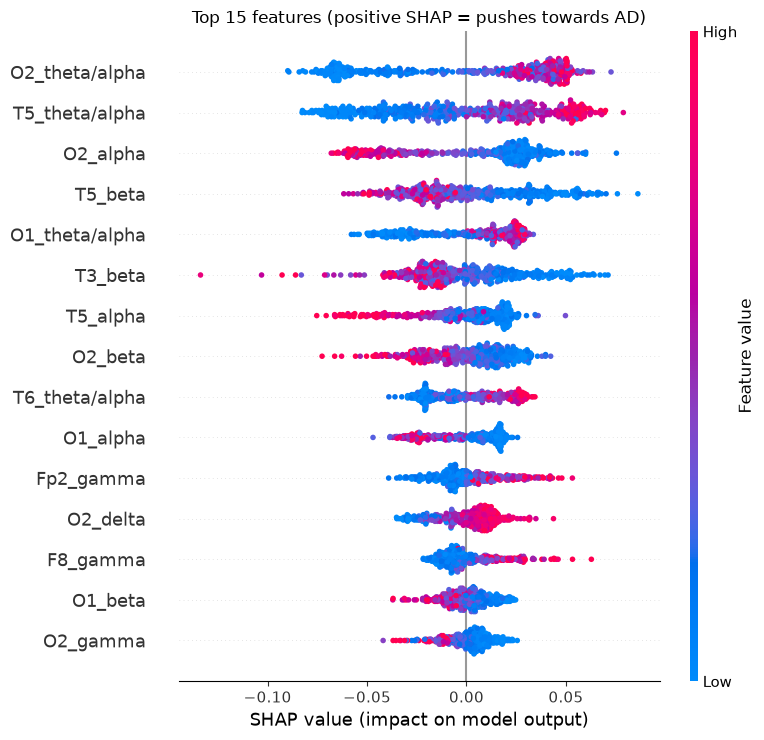

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
import shap
from src.features import load_spectra, feature_table, BANDS
from src.models import make_rf
from src.config import RESULTS

spec = load_spectra()
feats = feature_table(spec)
ad_cn = feats[feats.label.isin(["AD", "CN"])].reset_index(drop=True)
X = ad_cn.drop(columns=["subject", "label"])
y = (ad_cn.label == "AD").astype(int).values             # AD = 1, CN = 0
rf = make_rf().fit(X.values, y)

# SHAP on a random sample of epochs (all of them would be slow)
sample = X.sample(500, random_state=0)
values = shap.TreeExplainer(rf).shap_values(sample.values)
values = values[..., 1] if np.ndim(values) == 3 else values[1]    # contribution towards "AD"
shap.summary_plot(values, sample, max_display=15, show=False)
plt.title("Top 15 features (positive SHAP = pushes towards AD)")
plt.tight_layout()
plt.savefig(RESULTS / "shap_summary.png", dpi=120)
plt.show()

C:\Users\darsh\AppData\Local\Temp\ipykernel_16812\682998278.py:9: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  info.set_montage("standard_1020")


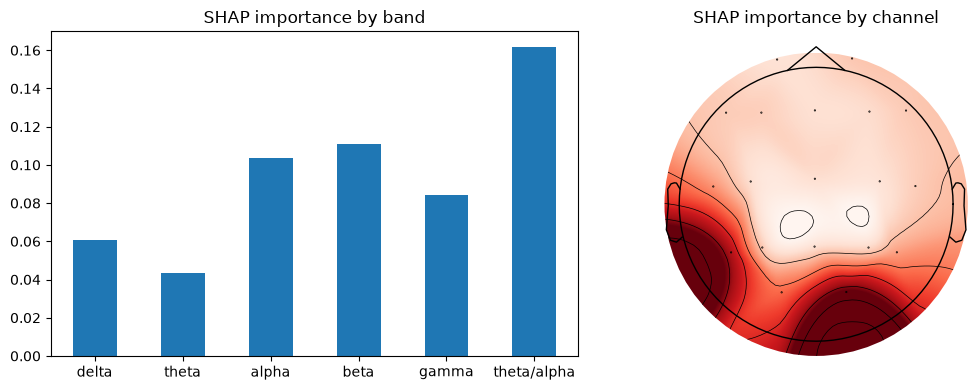

delta          0.0608
theta          0.0436
alpha          0.1038
beta           0.1109
gamma          0.0840
theta/alpha    0.1618
dtype: float64


In [2]:
# add up the importance by band and by channel
importance = pd.Series(np.abs(values).mean(axis=0), index=X.columns)
channel = importance.index.str.split("_").str[0]
band = importance.index.str.split("_").str[1]
by_band = importance.groupby(band).sum().reindex(list(BANDS) + ["theta/alpha"])
by_channel = importance.groupby(channel).sum().reindex(spec["ch_names"])

info = mne.create_info(spec["ch_names"], sfreq=500, ch_types="eeg")
info.set_montage("standard_1020")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_band.plot.bar(ax=axes[0], rot=0)
axes[0].set_title("SHAP importance by band")
mne.viz.plot_topomap(by_channel.values, info, axes=axes[1], show=False, cmap="Reds")
axes[1].set_title("SHAP importance by channel")
plt.tight_layout()
plt.savefig(RESULTS / "shap_bands_channels.png", dpi=120)
plt.show()
print(by_band.round(4))

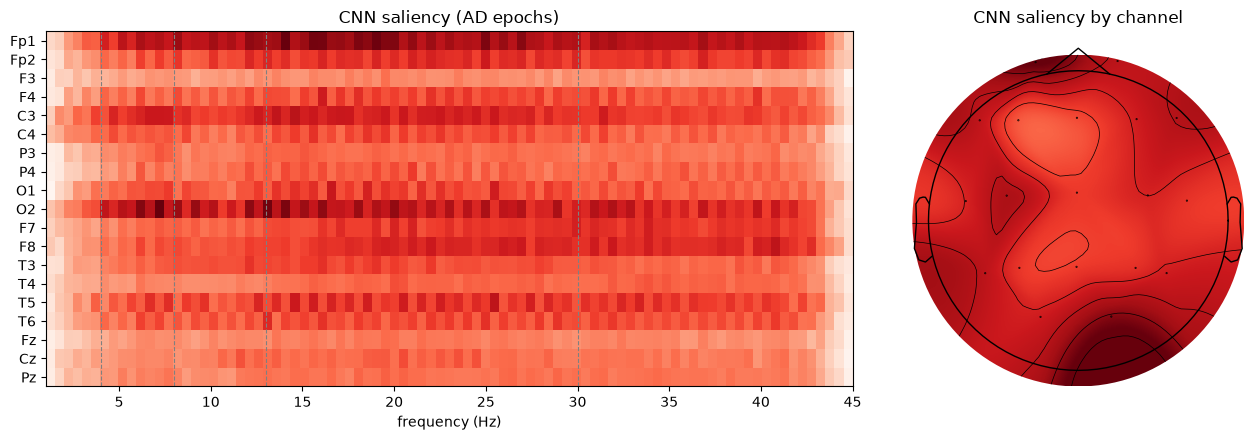

In [3]:
import torch
from src.models import CNNClassifier

keep = np.isin(spec["label"], ["AD", "CN"])
power = spec["power"][keep]
labels = spec["label"][keep]
cnn = CNNClassifier().fit(power.reshape(len(power), -1), (labels == "AD").astype(int))

# saliency: how much each (channel, frequency) input moves the AD score, on 1000 AD epochs
rng = np.random.default_rng(0)
ad_epochs = power[labels == "AD"][rng.choice((labels == "AD").sum(), 1000, replace=False)]
x = cnn.prepare(ad_epochs.reshape(len(ad_epochs), -1)).requires_grad_(True)
cnn.model.eval()
cnn.model(x)[:, 1].sum().backward()
saliency = (x.grad * x).abs().mean(axis=0).detach().numpy()       # (19 channels, 89 frequencies)

freqs = spec["freqs"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].imshow(saliency, aspect="auto", cmap="Reds", extent=[freqs[0], freqs[-1], len(saliency) - 0.5, -0.5])
axes[0].set_yticks(range(len(spec["ch_names"])))
axes[0].set_yticklabels(spec["ch_names"])
for edge in [4, 8, 13, 30]:
    axes[0].axvline(edge, color="gray", linestyle="--", linewidth=0.8)
axes[0].set_xlabel("frequency (Hz)")
axes[0].set_title("CNN saliency (AD epochs)")
mne.viz.plot_topomap(saliency.sum(axis=1), info, axes=axes[1], show=False, cmap="Reds")
axes[1].set_title("CNN saliency by channel")
plt.tight_layout()
plt.savefig(RESULTS / "cnn_saliency.png", dpi=120)
plt.show()